# Assignment 1
Group: 2023324 Mohammad Umar, 2023454 Saanvi Singh

In [1]:
import os
os.environ['LOKY_MAX_CPU_COUNT'] = str(max(1, os.cpu_count() - 1)) # silence joblib core-count warning
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_kddcup99
from sklearn.cluster import KMeans

SEED = 42
rng = np.random.default_rng(SEED)

### Data

In [2]:
kdd = fetch_kddcup99(subset=None, as_frame=True)
X = kdd.data.copy()

# one-hot encoding the 3 text features, rest to float
cat_cols = ['protocol_type', 'service', 'flag']
for c in cat_cols:
    X[c] = X[c].apply(lambda v: v.decode() if isinstance(v, bytes) else v)
X = pd.get_dummies(X, columns=cat_cols)
X = X.astype(float)

# dropping constant columns
X = X.loc[:, X.nunique() > 1]

# min-max rescaling
X = (X - X.min()) / (X.max() - X.min())

D = X.to_numpy(dtype=np.float32)
n, d = D.shape
print('n =', n, ' d =', d)

n = 494021  d = 116


### Q1

In [3]:
k = 15

def cost(D, B):
    # cost(D,B) = sum_i min_{b in B} ||D_i - b||^2
    dists = np.stack([((D - b)**2).sum(axis=1) for b in B], axis=1) # n x k squared distances
    return dists.min(axis=1).sum(dtype=np.float64)

def part_cost(X, labels):
    # cost_X(C) = sum_j sum_{i in C_j} ||X_i - mu_j(X)||^2
    X = np.asarray(X, dtype=np.float64)
    tot = 0.0
    for j in np.unique(labels):
        Xj = X[labels == j]
        tot += ((Xj - Xj.mean(0))**2).sum()
    return tot

def centres_from_labels(D, labels):
    # b_hat_j = (1/|C_j|) sum_{i in C_j} D_i
    return np.array([D[labels == j].mean(0) for j in np.unique(labels)])

def gauss(m, d):
    # A in R^{m x d}, iid N(0, 1/m)
    return rng.normal(0, 1/np.sqrt(m), size=(m, d)).astype(np.float32)

#### (a)

In [4]:
t0 = time.time()
km = KMeans(n_clusters=k, n_init=5, random_state=SEED).fit(D)
time_D = time.time() - t0

B = km.cluster_centers_
labels_D = km.labels_ # clusters C_D
cost_DB = cost(D, B)
print(f'cost(D,B) = {cost_DB:.2f}   time = {time_D:.2f} s')

cost(D,B) = 53498.07   time = 42.00 s


#### (b), (c), (d)

In [5]:
ms = [5, 10, 15, 20, 25]
reps = 5
rows = []
for m in ms:
    for r in range(reps):
        t0 = time.time()
        A = gauss(m, d)
        E = D @ A.T # E = D A^T, row i = A D_i
        kmE = KMeans(n_clusters=k, n_init=5, random_state=SEED + r).fit(E)
        t = time.time() - t0

        B_hat = centres_from_labels(D, kmE.labels_)
        A_pinv = np.linalg.pinv(A)
        B_plus = np.array([A_pinv @ a for a in kmE.cluster_centers_]) # A^+ a for each centre a

        c_hat = cost(D, B_hat)
        c_plus = cost(D, B_plus)
        rows.append(dict(m=m, rep=r, time=t, cost_hat=c_hat,
                         ratio_hat=c_hat / cost_DB, ratio_plus=c_plus / cost_DB))

res1 = pd.DataFrame(rows)
res1

,m,rep,time,cost_hat,ratio_hat,ratio_plus
0,5,0,6.231285,64248.607274,1.200952,78.973715
1,5,1,5.086223,68296.352688,1.276614,78.501666
2,5,2,5.042482,57401.881229,1.072971,79.804253
3,5,3,7.778497,62851.987737,1.174846,78.823915
4,5,4,8.360566,59010.901347,1.103047,75.527781
5,10,0,8.875938,54660.295639,1.021725,73.955240
6,10,1,8.903085,61720.455976,1.153695,76.000746
7,10,2,5.692119,58168.394050,1.087299,77.007865
8,10,3,5.369057,52775.752284,0.986498,76.866159
9,10,4,5.425745,55431.574582,1.036142,76.985934


In [6]:
summ1 = res1.groupby('m')[['ratio_hat', 'ratio_plus', 'time']].agg(['mean', 'min', 'max'])
summ1

ratio_hat                     ratio_plus                            time  \
        mean       min       max       mean        min        max      mean   
m                                                                             
5   1.165686  1.072971  1.276614  78.326266  75.527781  79.804253  6.499810   
10  1.057072  0.986498  1.153695  76.163189  73.955240  77.007865  6.853189   
15  1.057135  0.995038  1.167847  73.801926  69.473159  76.739161  6.257230   
20  1.007857  0.979686  1.050611  69.754902  66.354857  71.244444  7.294176   
25  1.031251  0.988544  1.050664  65.602733  63.827801  66.726385  7.945278   

                        
         min       max  
m                       
5   5.042482  8.360566  
10  5.369057  8.903085  
15  6.071282  6.471112  
20  7.112282  7.608993  
25  7.805995  8.271546

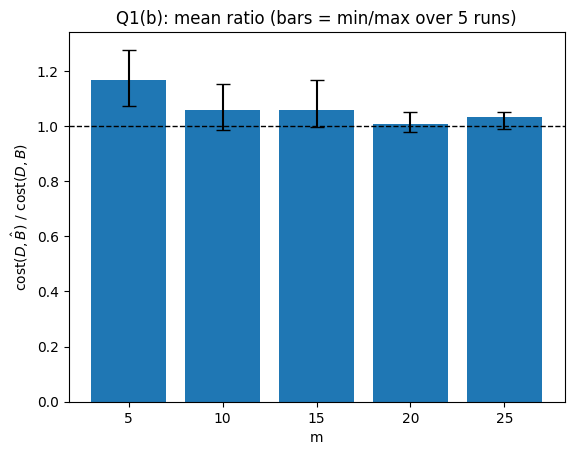

In [7]:
mean_r = summ1['ratio_hat']['mean']
err = [mean_r - summ1['ratio_hat']['min'], summ1['ratio_hat']['max'] - mean_r]
plt.bar([str(m) for m in ms], mean_r, yerr=err, capsize=5)
plt.axhline(1, color='k', ls='--', lw=1)
plt.xlabel('m'); plt.ylabel(r'cost$(D,\hat B)$ / cost$(D,B)$')
plt.title('Q1(b): mean ratio (bars = min/max over 5 runs)')
plt.show()

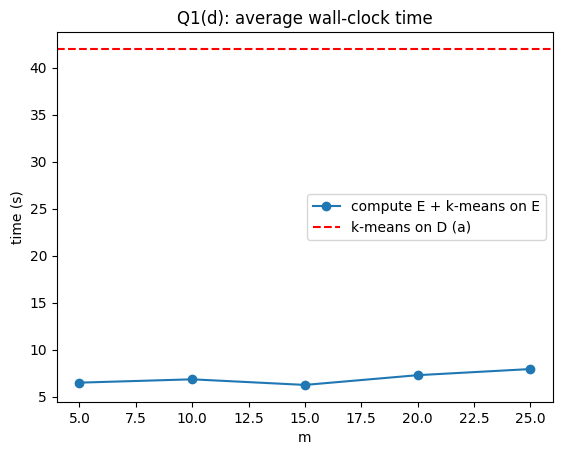

In [8]:
plt.plot(ms, summ1['time']['mean'], 'o-', label='compute E + k-means on E')
plt.axhline(time_D, color='r', ls='--', label='k-means on D (a)')
plt.xlabel('m'); plt.ylabel('time (s)'); plt.legend()
plt.title('Q1(d): average wall-clock time')
plt.show()

#### (e)

In [9]:
# 10^4 random pairs (i,l) with D_i != D_l, fixed for all m
npairs = 10**4
I, L = [], []
while len(I) < npairs:
    i = rng.integers(0, n, npairs)
    l = rng.integers(0, n, npairs)
    ok = ((D[i] - D[l])**2).sum(1) > 0
    I += list(i[ok]); L += list(l[ok])
I, L = np.array(I[:npairs]), np.array(L[:npairs])
dD = ((D[I] - D[L]).astype(np.float64)**2).sum(1)

costD_CD = part_cost(D, labels_D)
pair_ratios, cost_ratios = [], []
for m in ms:
    # (i) one A: ||E_i - E_l||^2 / ||D_i - D_l||^2
    A = gauss(m, d)
    dE = (((D[I] - D[L]) @ A.T).astype(np.float64)**2).sum(1)
    pair_ratios.append(dE / dD)
    # (ii) 20 A's: cost_E(C_D) / cost_D(C_D)
    ratios = []
    for _ in range(20):
        E = D @ gauss(m, d).T
        ratios.append(part_cost(E, labels_D) / costD_CD)
    cost_ratios.append(ratios)

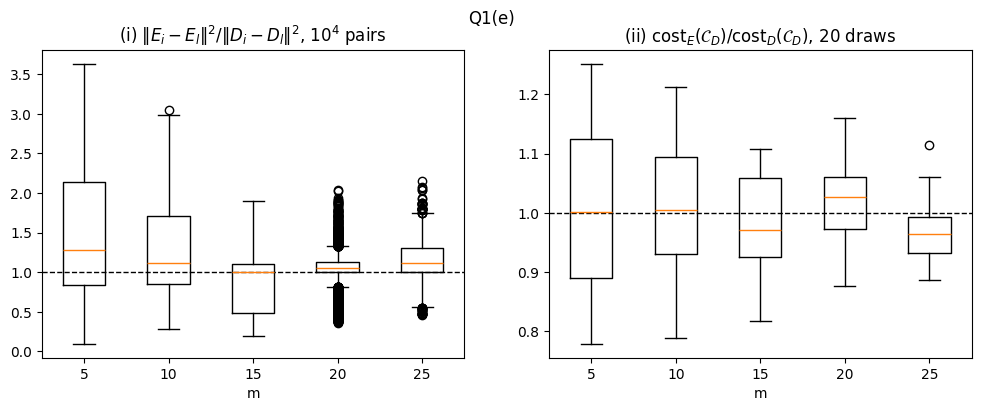

    m  pair_std  cost_std
0   5  0.664256  0.142820
1  10  0.526343  0.107235
2  15  0.379182  0.083630
3  20  0.219154  0.070060
4  25  0.217938  0.056454


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=False)
ax[0].boxplot(pair_ratios); ax[0].set_xticks(range(1, 6), ms)
ax[0].set_title(r'(i) $\|E_i-E_l\|^2/\|D_i-D_l\|^2$, $10^4$ pairs')
ax[1].boxplot(cost_ratios); ax[1].set_xticks(range(1, 6), ms)
ax[1].set_title(r'(ii) cost$_E(\mathcal{C}_D)$/cost$_D(\mathcal{C}_D)$, 20 draws')
for a in ax:
    a.axhline(1, color='k', ls='--', lw=1); a.set_xlabel('m')
plt.suptitle('Q1(e)')
plt.show()

print(pd.DataFrame({'m': ms,
                    'pair_std': [np.std(p) for p in pair_ratios],
                    'cost_std': [np.std(c) for c in cost_ratios]}))

### Q2

In [11]:
y = (kdd.target != b'normal.').to_numpy(dtype=float)
D64 = D.astype(np.float64)

def loss(D, y, a):
    # Loss(D,y,a) = ||D a - y||^2
    return float(((D @ a - y)**2).sum())

def countsketch(D, y, m):
    # S_{h(i),i} = sigma(i), row i of D added with sign sigma(i) to row h(i) of SD
    nn = D.shape[0]
    h = rng.integers(0, m, nn)
    s = rng.choice([-1.0, 1.0], nn)
    SD = np.zeros((m, D.shape[1])); Sy = np.zeros(m)
    np.add.at(SD, h, s[:, None] * D)
    np.add.at(Sy, h, s * y)
    return SD, Sy

print('rank(D) =', np.linalg.matrix_rank(D64))

rank(D) = 113


#### (a)

In [12]:
t0 = time.time()
b = np.linalg.lstsq(D64, y, rcond=None)[0]
time_b = time.time() - t0
loss_b = loss(D64, y, b)
print(f'Loss(D,y,b) = {loss_b:.4f}   time = {time_b:.3f} s')

Loss(D,y,b) = 2949.7888   time = 6.069 s


#### (b), (c)

In [13]:
ms2 = [50, 100, 200, 500, 1000, 2000, 5000]
rows = []
for m in ms2:
    for r in range(5):
        t0 = time.time()
        SD, Sy = countsketch(D64, y, m)
        a_t = np.linalg.lstsq(SD, Sy, rcond=None)[0]
        t = time.time() - t0
        L_t = loss(D64, y, a_t)
        rows.append(dict(m=m, rep=r, time=t, loss=L_t, ratio=L_t / loss_b,
                         sk_loss=float(((SD @ a_t - Sy)**2).sum()))) # ||S D a~ - S y||^2
res2 = pd.DataFrame(rows)
res2

,m,rep,time,loss,ratio,sk_loss
0,50,0,1.928049,11348.590197,3.847255,1.375618e-23
1,50,1,1.909720,10595.467525,3.591941,3.380073e-24
2,50,2,1.727839,9944.746125,3.371342,7.262097e-24
3,50,3,1.681770,8429.169044,2.857550,1.940246e-23
4,50,4,2.016648,13982.580729,4.740197,1.544292e-23
5,100,0,1.839158,40948.898575,13.881976,1.211603e-23
6,100,1,1.895698,20704.168435,7.018865,2.731027e-24
7,100,2,1.982014,46981.640491,15.927120,9.686518e-24
8,100,3,1.899761,30004.057232,10.171595,1.820926e-23
9,100,4,1.708869,31795.334067,10.778851,1.038026e-23


In [14]:
summ2 = res2.groupby('m')[['loss', 'ratio', 'sk_loss', 'time']].agg(['mean', 'min', 'max'])
summ2['time_full_b'] = time_b
summ2

loss                                  ratio            \
              mean           min           max       mean       min   
m                                                                     
50    10860.110724   8429.169044  13982.580729   3.681657  2.857550   
100   34086.819760  20704.168435  46981.640491  11.555681  7.018865   
200    6677.408175   5919.649389   7190.901985   2.263690  2.006804   
500    3794.792984   3559.172318   4050.602714   1.286463  1.206585   
1000   3340.722072   3285.771899   3420.805147   1.132529  1.113901   
2000   3127.280078   3097.333905   3157.901558   1.060171  1.050019   
5000   3010.437059   3006.845942   3016.238932   1.020560  1.019343   

                      sk_loss                                  time            \
            max          mean           min           max      mean       min   
m                                                                               
50     4.740197  1.184875e-23  3.380073e-24  1.940246e-23  1.852805  1.681770   
100   15.927120  1.062462e-23  2.731027e-24  1.820926e-23  1.865100  1.708869   
200    2.437768  1.198094e+03  1.052275e+03  1.283871e+03  1.666880  1.620641   
500    1.373184  2.163040e+03  2.070480e+03  2.265724e+03  1.583761  1.542775   
1000   1.159678  2.673916e+03  2.540135e+03  2.838088e+03  1.567151  1.551486   
2000   1.070552  2.733206e+03  2.583122e+03  2.839651e+03  1.616571  1.575677   
5000   1.022527  2.834879e+03  2.801456e+03  2.891763e+03  1.709247  1.673247   

               time_full_b  
           max              
m                           
50    2.016648    6.069324  
100   1.982014    6.069324  
200   1.732119    6.069324  
500   1.654442    6.069324  
1000  1.615707    6.069324  
2000  1.672358    6.069324  
5000  1.751428    6.069324

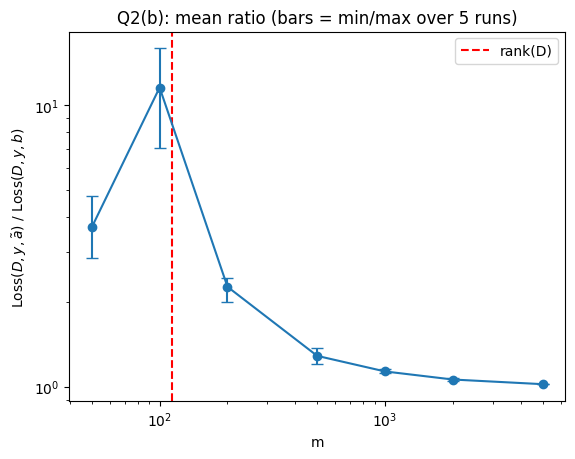

In [15]:
mr = summ2['ratio']['mean']
plt.errorbar(ms2, mr, yerr=[mr - summ2['ratio']['min'], summ2['ratio']['max'] - mr], fmt='o-', capsize=4)
plt.axvline(np.linalg.matrix_rank(D64), color='r', ls='--', label='rank(D)')
plt.xscale('log'); plt.yscale('log')
plt.xlabel('m'); plt.ylabel(r'Loss$(D,y,\tilde a)$ / Loss$(D,y,b)$'); plt.legend()
plt.title('Q2(b): mean ratio (bars = min/max over 5 runs)')
plt.show()

#### (d)

m=50: mean=0.9937  std=0.1912
m=500: mean=0.9943  std=0.0677
m=5000: mean=1.0013  std=0.0237


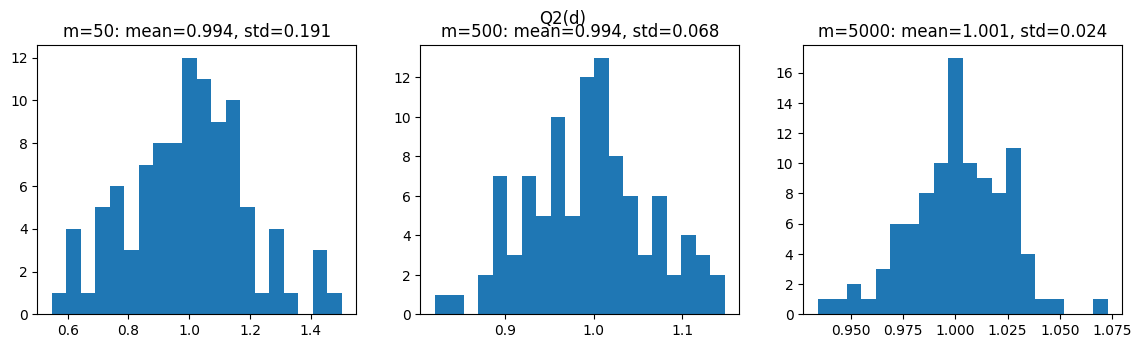

In [16]:
v = D64 @ b - y # residual of the full solution
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
for a, m in zip(ax, [50, 500, 5000]):
    vals = []
    for _ in range(100):
        h = rng.integers(0, m, n); s = rng.choice([-1.0, 1.0], n)
        Sv = np.zeros(m); np.add.at(Sv, h, s * v)
        vals.append((Sv**2).sum() / (v**2).sum()) # ||Sv||^2 / ||v||^2
    vals = np.array(vals)
    a.hist(vals, bins=20); a.set_title(f'm={m}: mean={vals.mean():.3f}, std={vals.std():.3f}')
    print(f'm={m}: mean={vals.mean():.4f}  std={vals.std():.4f}')
plt.suptitle('Q2(d)'); plt.show()

#### (e)

In [17]:
sub = np.random.default_rng(SEED).choice(n, 50000, replace=False) # fixed subset
D1, y1 = D64[sub], y[sub]
b1 = np.linalg.lstsq(D1, y1, rcond=None)[0]
loss_b1 = loss(D1, y1, b1)

m = 500
rows = []
for r in range(5):
    # (i) CountSketch
    t0 = time.time(); SD, Sy = countsketch(D1, y1, m); t_cs = time.time() - t0
    a_cs = np.linalg.lstsq(SD, Sy, rcond=None)[0]
    # (ii) dense S with iid N(0,1/m)
    t0 = time.time()
    S = rng.normal(0, 1/np.sqrt(m), size=(m, 50000))
    SD, Sy = S @ D1, S @ y1
    t_g = time.time() - t0
    a_g = np.linalg.lstsq(SD, Sy, rcond=None)[0]
    rows.append(dict(time_cs=t_cs, ratio_cs=loss(D1, y1, a_cs) / loss_b1,
                     time_gauss=t_g, ratio_gauss=loss(D1, y1, a_g) / loss_b1))
res3 = pd.DataFrame(rows)
print(res3.mean())

time_cs        0.146621
ratio_cs       1.298735
time_gauss     1.036927
ratio_gauss    1.279390
dtype: float64
